# E2 · Teardown de DINOv2 + intervención preliminar con LoRA
**1INF52 Deep Learning · Tarea académica final · Clasificación de cobertura del suelo (EuroSAT RGB) con DINOv2 ViT-S/14**

Este notebook cubre el entregable E2:
1. **Datos:** descarga de EuroSAT RGB, partición estratificada con semilla fija (guardada en disco).
2. **Fase A — Teardown del modelo base:** parámetros y FLOPs por bloque, latencia y memoria, características intermedias (PCA de tokens y atención), campo receptivo efectivo.
3. **Línea base:** DINOv2 congelado + clasificador lineal (*linear probing*).
4. **Fase B preliminar:** LoRA (rango 8) en Q y V de los 2 últimos bloques, comparada contra la línea base con el **mismo presupuesto**.

Todas las tablas y figuras se guardan en `results/` y `figures/` para el cuaderno de decisiones (`DESIGN_LOG.md`).

### Cómo ejecutarlo
- **Recomendado: Google Colab con GPU** → *Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)*. Todo el notebook tarda ~30–60 min.
- **CPU (sin GPU):** funciona, pero pon `MAX_POR_CLASE = 200` en la configuración para usar un subconjunto.
- Una AMD RX 580 no sirve para PyTorch (no tiene soporte CUDA ni ROCm actual), por eso se recomienda Colab.

In [ ]:
# Instalación (en Colab torch y torchvision ya vienen instalados)
!pip -q install "transformers>=4.40" scikit-learn pandas matplotlib tqdm

## 0. Configuración y reproducibilidad
Todas las decisiones que se pueden cambiar están aquí. Si cambias algo, **regístralo en `DESIGN_LOG.md`**.

In [ ]:
import os, json, time, math, random, glob, zipfile, platform
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import transforms
from tqdm.auto import tqdm
import transformers
from transformers import Dinov2Model

# ---------------- CONFIGURACIÓN ----------------
SEMILLA        = 42
MODELO_ID      = 'facebook/dinov2-small'     # ViT-S/14 sin registros (mismos pesos que torch.hub dinov2_vits14)
IMG_SIZE       = 224                          # 224/14 = 16x16 = 256 parches + 1 token CLS
DATA_DIR       = 'data/EuroSAT_RGB'
EUROSAT_URL    = 'https://zenodo.org/records/7711810/files/EuroSAT_RGB.zip'
MAX_POR_CLASE  = None                         # None = dataset completo (27,000). En CPU usa 200.
FRAC_VAL, FRAC_TEST = 0.15, 0.15              # partición interna estratificada 70/15/15
BATCH          = 64
EPOCAS         = 8                            # MISMO presupuesto para línea base y LoRA
LR             = 1e-3
WEIGHT_DECAY   = 1e-4
LORA_RANGO, LORA_ALPHA, LORA_DROPOUT = 8, 8, 0.0
LORA_BLOQUES   = [10, 11]                     # los 2 últimos de 12 bloques (índices desde 0)
# -----------------------------------------------

def fijar_semilla(seed=SEMILLA):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
fijar_semilla()

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
USAR_AMP = DEVICE == 'cuda'                   # precisión mixta (fp16) solo en GPU
for d in ('results', 'figures', 'checkpoints', 'splits'): os.makedirs(d, exist_ok=True)

ENTORNO = {
    'python': platform.python_version(), 'torch': torch.__version__, 'torchvision': torchvision.__version__,
    'transformers': transformers.__version__, 'device': DEVICE,
    'gpu': torch.cuda.get_device_name(0) if DEVICE == 'cuda' else None,
    'cpu': platform.processor() or platform.machine(), 'semilla': SEMILLA,
}
json.dump(ENTORNO, open('results/entorno.json', 'w'), indent=2)
print(json.dumps(ENTORNO, indent=2))

{
  "python": "3.13.15",
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "transformers": "5.20.1",
  "device": "cuda",
  "gpu": "Tesla T4",
  "cpu": "x86_64",
  "semilla": 42
}


## 1. Datos: EuroSAT RGB
27,000 imágenes Sentinel-2 de 64×64 px en 10 clases. Fuente: Helber et al. (2019), Zenodo 7711810 (licencia MIT + términos Copernicus Sentinel).

**Decisiones registradas:**
- **Preprocesamiento:** redimensionar 64 → 224 (bicúbico) **sin recorte** (recortar quitaría ~12 % del borde de una imagen ya pequeña) y normalizar con media/desviación de ImageNet, que es la normalización con la que se preentrenó DINOv2.
- **Partición para E2:** estratificada aleatoria 70/15/15 con semilla fija. **No es la partición geográfica** de la Fase C: los JPG RGB no traen coordenadas. Se usa solo como prueba interna y se declara así en el cuaderno.

In [ ]:
def encontrar_raiz_clases(base):
    # Busca la carpeta que contiene las 10 subcarpetas de clases (el zip puede traer niveles extra)
    for raiz, dirs, _ in os.walk(base):
        if len(dirs) == 10 and all(len(glob.glob(os.path.join(raiz, d, '*.jpg'))) > 0 for d in dirs):
            return raiz
    return None

if encontrar_raiz_clases(DATA_DIR) is None:
    os.makedirs('data', exist_ok=True)
    zip_path = 'data/EuroSAT_RGB.zip'
    if not os.path.exists(zip_path):
        print('Descargando EuroSAT RGB (~90 MB)...')
        torch.hub.download_url_to_file(EUROSAT_URL, zip_path)
    with zipfile.ZipFile(zip_path) as z: z.extractall(DATA_DIR)
RAIZ = encontrar_raiz_clases(DATA_DIR)
assert RAIZ is not None, 'No se encontró la carpeta con las 10 clases. Descarga EuroSAT_RGB.zip manualmente y descomprímelo en data/EuroSAT_RGB'
print('Raíz de clases:', RAIZ)

Descargando EuroSAT RGB (~90 MB)...


100%|██████████| 90.3M/90.3M [01:45<00:00, 896kB/s] 


Raíz de clases: data/EuroSAT_RGB/EuroSAT_RGB


Clases: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Imágenes por clase: {'AnnualCrop': np.int64(3000), 'Forest': np.int64(3000), 'HerbaceousVegetation': np.int64(3000), 'Highway': np.int64(2500), 'Industrial': np.int64(2500), 'Pasture': np.int64(2000), 'PermanentCrop': np.int64(2500), 'Residential': np.int64(3000), 'River': np.int64(2500), 'SeaLake': np.int64(3000)}
train 18900 | val 4050 | test 4050 → guardado en splits/split_seed42.json


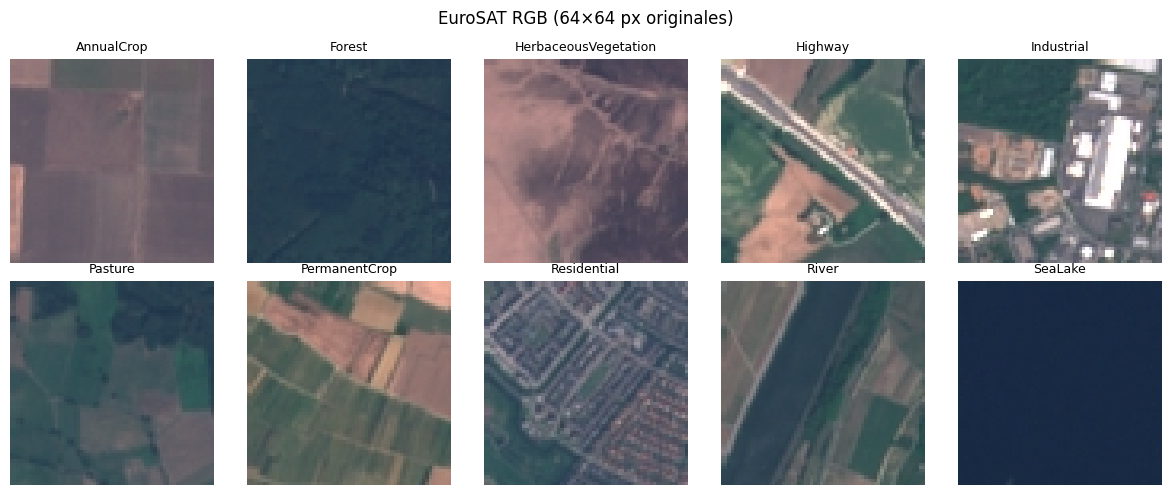

In [ ]:
MEDIA, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
tf_eval = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=transforms.InterpolationMode.BICUBIC),
    transforms.ToTensor(), transforms.Normalize(MEDIA, STD)])

dataset = torchvision.datasets.ImageFolder(RAIZ, transform=tf_eval)
CLASES = dataset.classes
etiquetas = np.array(dataset.targets)
print('Clases:', CLASES)
print('Imágenes por clase:', dict(zip(CLASES, np.bincount(etiquetas))))

def particion_estratificada(y, frac_val, frac_test, seed, max_por_clase=None):
    rng = np.random.default_rng(seed); tr, va, te = [], [], []
    for c in np.unique(y):
        idx = np.where(y == c)[0]; rng.shuffle(idx)
        if max_por_clase: idx = idx[:max_por_clase]
        n_te, n_va = int(round(len(idx) * frac_test)), int(round(len(idx) * frac_val))
        te += idx[:n_te].tolist(); va += idx[n_te:n_te + n_va].tolist(); tr += idx[n_te + n_va:].tolist()
    return sorted(tr), sorted(va), sorted(te)

ruta_split = f'splits/split_seed{SEMILLA}' + (f'_max{MAX_POR_CLASE}' if MAX_POR_CLASE else '') + '.json'
if os.path.exists(ruta_split):            # reutilizar la MISMA partición en todas las ejecuciones
    sp = json.load(open(ruta_split)); idx_tr, idx_va, idx_te = sp['train'], sp['val'], sp['test']
else:
    idx_tr, idx_va, idx_te = particion_estratificada(etiquetas, FRAC_VAL, FRAC_TEST, SEMILLA, MAX_POR_CLASE)
    rel = lambda ids: [os.path.relpath(dataset.samples[i][0], RAIZ) for i in ids]
    json.dump({'train': idx_tr, 'val': idx_va, 'test': idx_te,
               'archivos_test': rel(idx_te), 'semilla': SEMILLA}, open(ruta_split, 'w'))
print(f'train {len(idx_tr)} | val {len(idx_va)} | test {len(idx_te)} → guardado en {ruta_split}')

def cargador(indices, shuffle=False):
    g = torch.Generator(); g.manual_seed(SEMILLA)
    return DataLoader(Subset(dataset, indices), batch_size=BATCH, shuffle=shuffle, generator=g,
                      num_workers=2, pin_memory=(DEVICE == 'cuda'))
dl_tr, dl_va, dl_te = cargador(idx_tr), cargador(idx_va), cargador(idx_te)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, c in zip(axes.flat, range(len(CLASES))):
    i = int(np.where(etiquetas == c)[0][0])
    ax.imshow(plt.imread(dataset.samples[i][0])); ax.set_title(CLASES[c], fontsize=9); ax.axis('off')
plt.suptitle('EuroSAT RGB (64×64 px originales)'); plt.tight_layout(); plt.savefig('figures/00_muestras.png', dpi=120); plt.show()

## 2. Modelo base: DINOv2 ViT-S/14
- 12 bloques Transformer, dimensión 384, 6 cabezas de atención, MLP de 1,536.
- Una imagen de 224×224 se corta en parches de 14×14 → **16×16 = 256 tokens de parche + 1 token CLS = 257 tokens**.
- Se usa la implementación de Hugging Face porque tiene Q, K y V **separadas** (en `torch.hub`, `dinov2_vits14` las tiene fusionadas en una sola capa `qkv`, lo que complica aplicar LoRA solo a Q y V).

In [ ]:
def cargar_dinov2(**kw):
    m = Dinov2Model.from_pretrained(MODELO_ID, **kw)
    return m.eval().to(DEVICE)

modelo = cargar_dinov2()
for p in modelo.parameters(): p.requires_grad_(False)
print(modelo.config)

def cargar_dinov2_eager():
    # Atención "eager" (operaciones explícitas): necesaria para obtener mapas de atención y para que
    # el contador de FLOPs vea la atención (el kernel optimizado SDPA a veces no se cuenta).
    try:
        m = cargar_dinov2(attn_implementation='eager')
    except TypeError:
        m = cargar_dinov2(); m.set_attn_implementation('eager')
    for p in m.parameters(): p.requires_grad_(False)
    return m

def salida_bloque(out):
    # Según la versión de transformers, cada bloque devuelve un tensor o una tupla
    return out[0] if isinstance(out, (tuple, list)) else out

with torch.no_grad():
    x = torch.randn(2, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)
    o = modelo(pixel_values=x)
print('last_hidden_state:', tuple(o.last_hidden_state.shape), '| pooler (CLS):', tuple(o.pooler_output.shape))

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Dinov2Config {
  "apply_layernorm": true,
  "architectures": [
    "Dinov2Model"
  ],
  "attention_probs_dropout_prob": 0.0,
  "drop_path_rate": 0.0,
  "dtype": "float32",
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.0,
  "hidden_size": 384,
  "image_size": 518,
  "initializer_range": 0.02,
  "layer_norm_eps": 1e-06,
  "layerscale_value": 1.0,
  "mlp_ratio": 4,
  "model_type": "dinov2",
  "num_attention_heads": 6,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "out_features": [
    "stage12"
  ],
  "out_indices": [
    12
  ],
  "patch_size": 14,
  "qkv_bias": true,
  "reshape_hidden_states": true,
  "stage_names": [
    "stem",
    "stage1",
    "stage2",
    "stage3",
    "stage4",
    "stage5",
    "stage6",
    "stage7",
    "stage8",
    "stage9",
    "stage10",
    "stage11",
    "stage12"
  ],
  "transformers_version": "5.20.1",
  "use_mask_token": true,
  "use_swiglu_ffn": false
}

last_hidden_state: (2, 257, 384) | pooler (CLS): (2, 384)


## 3. Fase A — Teardown del modelo base

### 3.1 Parámetros por bloque

bloque
embeddings          753024
bloque_01          1775232
bloque_02          1775232
bloque_03          1775232
bloque_04          1775232
bloque_05          1775232
bloque_06          1775232
bloque_07          1775232
bloque_08          1775232
bloque_09          1775232
bloque_10          1775232
bloque_11          1775232
bloque_12          1775232
layernorm_final        768

TOTAL: 22,056,576 parámetros (88.2 MB en fp32)

Un bloque por componente:
 componente  parametros
  atencion      591360
       mlp     1181568
    normas        1536
layerscale         768

Nota: position_embeddings tiene forma (1, 1370, 384) → pensado para 518 px (37×37+1 tokens); a 224 px se interpola a 16×16+1.


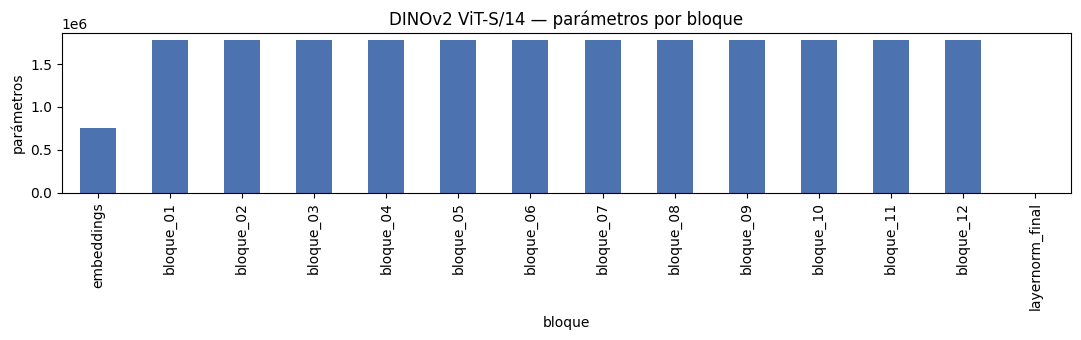

In [ ]:
def contar(mod): return sum(p.numel() for p in mod.parameters())

filas = [{'bloque': 'embeddings', 'componente': n, 'parametros': p.numel()} for n, p in modelo.embeddings.named_parameters()]
for i, capa in enumerate(modelo.encoder.layer):
    grupos = {'atencion': 0, 'mlp': 0, 'normas': 0, 'layerscale': 0}
    for n, p in capa.named_parameters():
        k = 'atencion' if 'attention' in n else 'mlp' if 'mlp' in n else 'normas' if 'norm' in n else 'layerscale'
        grupos[k] += p.numel()
    for k, v in grupos.items(): filas.append({'bloque': f'bloque_{i + 1:02d}', 'componente': k, 'parametros': v})
filas.append({'bloque': 'layernorm_final', 'componente': 'norma', 'parametros': contar(modelo.layernorm)})
df_params = pd.DataFrame(filas)
df_params.to_csv('results/A1_parametros_detalle.csv', index=False)

por_bloque = df_params.groupby('bloque', sort=False)['parametros'].sum()
print(por_bloque.to_string()); print(f'\nTOTAL: {contar(modelo):,} parámetros ({contar(modelo) * 4 / 1e6:.1f} MB en fp32)')
print('\nUn bloque por componente:\n', df_params[df_params.bloque == 'bloque_01'][['componente', 'parametros']].to_string(index=False))
emb = dict(modelo.embeddings.named_parameters())
print('\nNota: position_embeddings tiene forma', tuple(emb[[k for k in emb if 'position' in k][0]].shape),
      '→ pensado para 518 px (37×37+1 tokens); a 224 px se interpola a 16×16+1.')

ax = por_bloque.plot.bar(figsize=(11, 3.5), color='#4C72B0'); ax.set_ylabel('parámetros')
ax.set_title('DINOv2 ViT-S/14 — parámetros por bloque'); plt.tight_layout(); plt.savefig('figures/A1_parametros.png', dpi=120); plt.show()

**Para el cuaderno:** los 12 bloques son idénticos (~1.78 M cada uno). Dentro de un bloque, el **MLP tiene ~2/3 de los parámetros** (384→1536→384) y la atención ~1/3 (Q, K, V y salida, 384×384 cada una). Los embeddings pesan poco salvo la tabla de posiciones.

### 3.2 FLOPs por bloque (medidos y analíticos)
Se mide con la versión *eager* de la atención; con la implementación optimizada (SDPA) el contador puede omitir la parte de atención y reportar ~10 % menos.

**Convención:** 1 multiplicación-suma (MAC) = **2 FLOPs**, la convención de `torch.utils.flop_counter`. Herramientas como `fvcore` o `thop` reportan MACs y las llaman "FLOPs", así que sus números salen a la mitad. Indícalo siempre.

Fórmula analítica por bloque, con N tokens y dimensión D (en MACs):
- Q, K, V y proyección de salida: 4·N·D²
- Atención (QKᵀ y pesos × V): 2·N²·D  ← **cuadrático en el número de tokens**
- MLP (D → 4D → D): 8·N·D²

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

A 224px (257 tokens): medido = 12.25 GFLOPs | analítico = 12.25 GFLOPs
Por bloque: medido = 1.011 | analítico = 1.011 GFLOPs (de los cuales la parte cuadrática de la atención = 0.101)

  img_size  tokens  GFLOPs_total  % atención cuadrática
      112      65          2.87                    2.7
      224     257         12.25                    9.9
      448    1025         63.36                   30.6


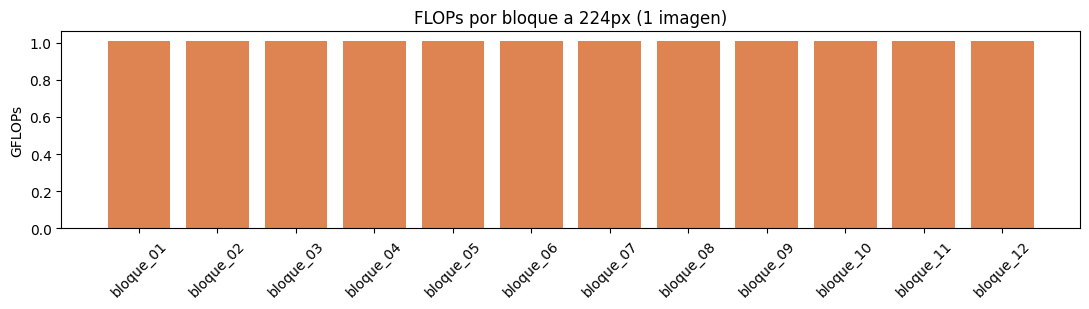

In [ ]:
from torch.utils.flop_counter import FlopCounterMode

def flops_por_bloque(m, img_size):
    x = torch.randn(1, 3, img_size, img_size, device=DEVICE)
    with FlopCounterMode(display=False) as fc, torch.no_grad():
        m(pixel_values=x)
    cuentas = fc.get_flop_counts(); total = fc.get_total_flops()
    fila = {'img_size': img_size, 'tokens': (img_size // 14) ** 2 + 1, 'GFLOPs_total': total / 1e9}
    for k, v in cuentas.items():
        partes = k.split('.')
        if 'layer' in partes and partes[-1].isdigit() and partes[-2] == 'layer':
            fila[f'bloque_{int(partes[-1]) + 1:02d}'] = sum(v.values()) / 1e9
        elif partes[-1] == 'embeddings':
            fila['embeddings'] = sum(v.values()) / 1e9
    return fila

def flops_analiticos(img_size, D=384, L=12, p=14):
    N = (img_size // p) ** 2 + 1
    macs_bloque = 4 * N * D ** 2 + 2 * N ** 2 * D + 8 * N * D ** 2
    macs_patch = (N - 1) * (3 * p * p) * D
    return 2 * (L * macs_bloque + macs_patch) / 1e9, 2 * macs_bloque / 1e9, 2 * (2 * N ** 2 * D) / 1e9

modelo_eager = cargar_dinov2_eager()
medido = flops_por_bloque(modelo_eager, IMG_SIZE)
total_a, bloque_a, atn_a = flops_analiticos(IMG_SIZE)
print(f"A {IMG_SIZE}px ({medido['tokens']} tokens): medido = {medido['GFLOPs_total']:.2f} GFLOPs | analítico = {total_a:.2f} GFLOPs")
print(f"Por bloque: medido = {medido.get('bloque_01', float('nan')):.3f} | analítico = {bloque_a:.3f} GFLOPs "
      f"(de los cuales la parte cuadrática de la atención = {atn_a:.3f})")

# ¿Cómo escala el costo con la resolución? (clave: las imágenes originales son de 64 px)
escala = []
for s in (112, 224, 448):
    t, b, a = flops_analiticos(s)
    escala.append({'img_size': s, 'tokens': (s // 14) ** 2 + 1, 'GFLOPs_total': round(t, 2), '% atención cuadrática': round(100 * 12 * a / t, 1)})
df_escala = pd.DataFrame(escala); print('\n', df_escala.to_string(index=False))
pd.DataFrame([medido]).to_csv('results/A2_flops_por_bloque.csv', index=False); df_escala.to_csv('results/A2_flops_vs_resolucion.csv', index=False)

bloques = {k: v for k, v in medido.items() if k.startswith('bloque')}
plt.figure(figsize=(11, 3.2)); plt.bar(list(bloques), list(bloques.values()), color='#DD8452')
plt.xticks(rotation=45); plt.ylabel('GFLOPs'); plt.title(f'FLOPs por bloque a {IMG_SIZE}px (1 imagen)')
plt.tight_layout(); plt.savefig('figures/A2_flops.png', dpi=120); plt.show()

**Para el cuaderno:** el costo es igual en los 12 bloques (todos procesan 257 tokens de dimensión 384; un ViT no reduce resolución como una CNN). Duplicar la resolución cuadruplica los tokens, y la parte de atención crece con N². Como EuroSAT tiene solo 64×64 px, subirla a 224 genera **~12 GFLOPs por imagen para información que originalmente cabía en 64×64**: ese es el precio de usar el modelo en su resolución nativa.

### 3.3 Latencia y memoria
Medición con **calentamiento** (las primeras pasadas son lentas por inicialización), **sincronización de GPU** (las operaciones CUDA son asíncronas) y varias repeticiones (mediana).

In [ ]:
def medir_latencia(m, batch, img_size=IMG_SIZE, reps=20, warmup=5, amp=False):
    x = torch.randn(batch, 3, img_size, img_size, device=DEVICE)
    if DEVICE == 'cuda': torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    tiempos = []
    with torch.no_grad(), torch.autocast(device_type='cuda', dtype=torch.float16, enabled=amp):
        for i in range(warmup + reps):
            if DEVICE == 'cuda': torch.cuda.synchronize()
            t0 = time.perf_counter(); m(pixel_values=x)
            if DEVICE == 'cuda': torch.cuda.synchronize()
            if i >= warmup: tiempos.append(time.perf_counter() - t0)
    med = float(np.median(tiempos))
    mem = torch.cuda.max_memory_allocated() / 2 ** 20 if DEVICE == 'cuda' else float('nan')
    return {'batch': batch, 'precision': 'fp16' if amp else 'fp32', 'ms_por_batch': med * 1e3,
            'ms_por_imagen': med * 1e3 / batch, 'imagenes_por_s': batch / med, 'memoria_pico_MB': mem}

lotes = (1, 32, 128) if DEVICE == 'cuda' else (1, 16)
lat = [medir_latencia(modelo, b) for b in lotes]
if USAR_AMP: lat += [medir_latencia(modelo, b, amp=True) for b in lotes]
df_lat = pd.DataFrame(lat).round(2); df_lat['device'] = ENTORNO['gpu'] or ENTORNO['cpu']
df_lat.to_csv('results/A3_latencia_memoria.csv', index=False); print(df_lat.to_string(index=False))
print(f"\nMemoria solo de pesos: {contar(modelo) * 4 / 2**20:.1f} MB (fp32)")

 batch precision  ms_por_batch  ms_por_imagen  imagenes_por_s  memoria_pico_MB   device
     1      fp32          8.89           8.89          112.46           187.10 Tesla T4
    32      fp32        121.48           3.80          263.41           343.96 Tesla T4
   128      fp32        492.99           3.85          259.64           833.27 Tesla T4
     1      fp16         39.47          39.47           25.33           186.04 Tesla T4
    32      fp16         39.97           1.25          800.65           295.77 Tesla T4
   128      fp16        149.94           1.17          853.70           640.52 Tesla T4

Memoria solo de pesos: 84.1 MB (fp32)


**Para el cuaderno:** reporta el hardware (columna `device`). Con batch 1 la GPU está subutilizada (domina la latencia fija); con batches grandes sube el throughput (imágenes/s). La memoria pico crece con el batch por las activaciones, no por los pesos.

### 3.4 Características intermedias
1. **PCA de los tokens de parche → RGB:** se proyectan los 384 valores de cada parche a 3 componentes principales y se pintan como colores. Parches con colores parecidos = representaciones parecidas. Se compara en los bloques 4, 8 y 12.
2. **Atención del token CLS** en el último bloque: qué parches "mira" el modelo para resumir la imagen.

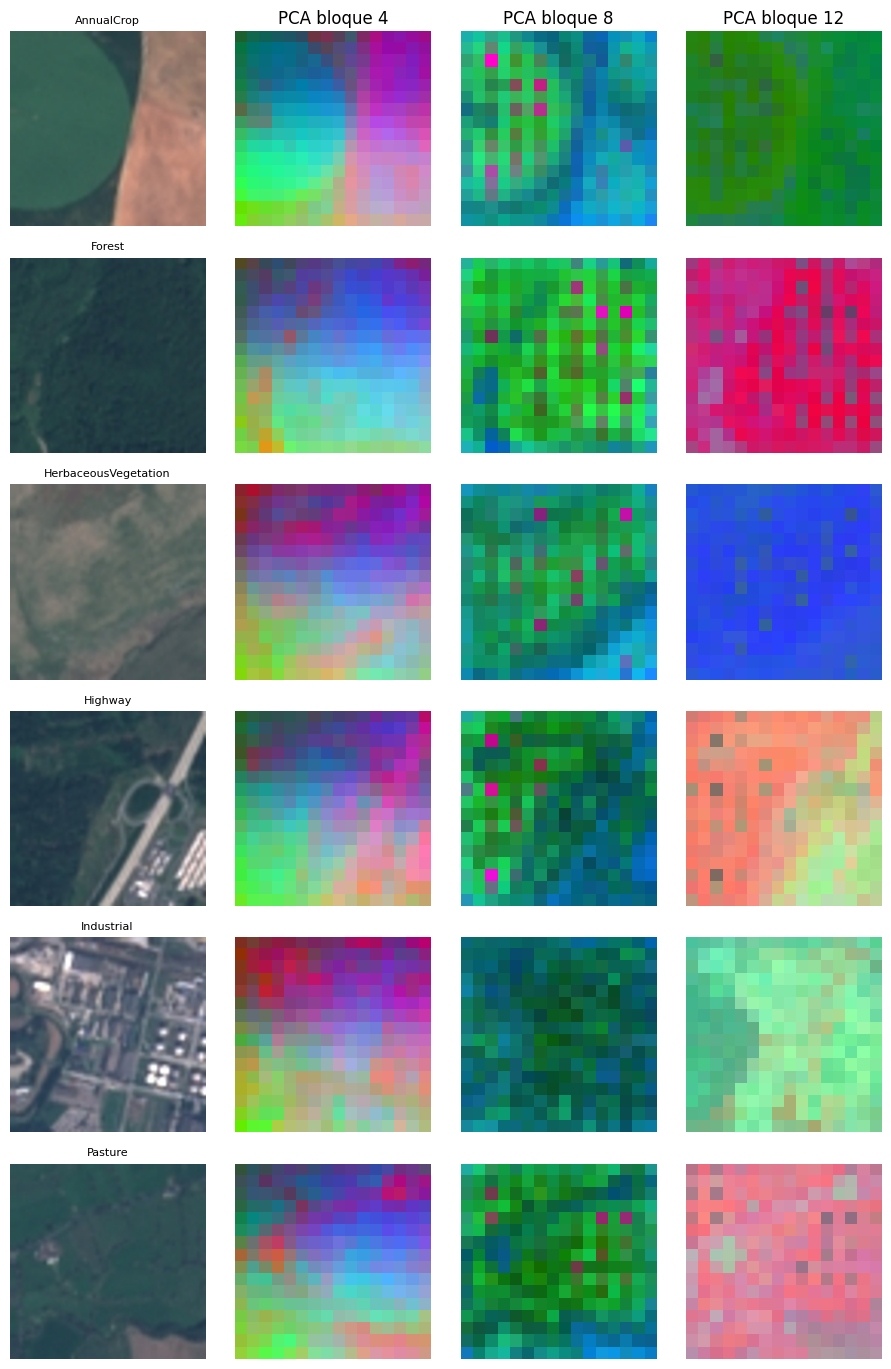

In [ ]:
from sklearn.decomposition import PCA
fijar_semilla()
idx_vis = [int(np.where(etiquetas[idx_te] == c)[0][0]) for c in range(len(CLASES))][:6]
x_vis = torch.stack([dataset[idx_te[i]][0] for i in idx_vis]).to(DEVICE)
G = IMG_SIZE // 14
with torch.no_grad():
    hs = modelo(pixel_values=x_vis, output_hidden_states=True).hidden_states   # 13: embeddings + 12 bloques

def desnormalizar(t):
    return (t.cpu().permute(1, 2, 0) * torch.tensor(STD) + torch.tensor(MEDIA)).clamp(0, 1).numpy()

bloques_vis = [4, 8, 12]
fig, axes = plt.subplots(len(idx_vis), 1 + len(bloques_vis), figsize=(2.3 * (1 + len(bloques_vis)), 2.3 * len(idx_vis)))
for j, b in enumerate(bloques_vis):
    tokens = hs[b][:, 1:, :].reshape(-1, hs[b].shape[-1]).float().cpu().numpy()  # sin el CLS
    comp = PCA(n_components=3, random_state=SEMILLA).fit_transform(tokens)
    comp = (comp - comp.min(0)) / (comp.max(0) - comp.min(0) + 1e-8)
    comp = comp.reshape(len(idx_vis), G, G, 3)
    for i in range(len(idx_vis)):
        axes[i, j + 1].imshow(comp[i]); axes[i, j + 1].axis('off')
        if i == 0: axes[i, j + 1].set_title(f'PCA bloque {b}')
for i in range(len(idx_vis)):
    axes[i, 0].imshow(desnormalizar(x_vis[i])); axes[i, 0].axis('off')
    axes[i, 0].set_title(CLASES[etiquetas[idx_te[idx_vis[i]]]], fontsize=8)
plt.tight_layout(); plt.savefig('figures/A4_pca_tokens.png', dpi=120); plt.show()

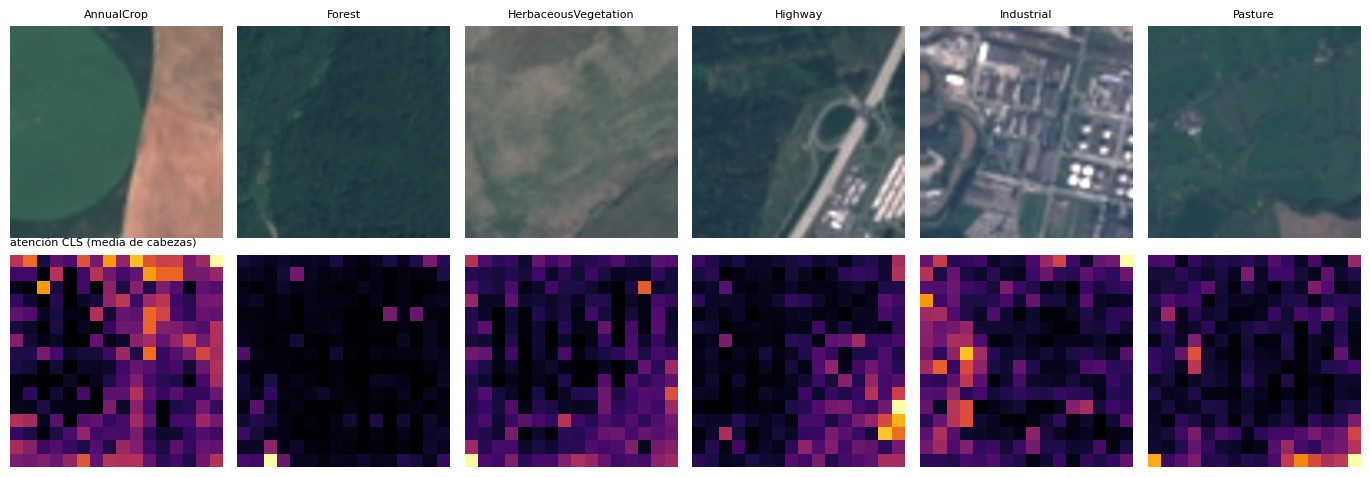

In [ ]:
# Atención CLS → parches del último bloque (necesita la implementación "eager" de la atención)
with torch.no_grad():
    att = modelo_eager(pixel_values=x_vis, output_attentions=True).attentions[-1]   # (B, cabezas, 257, 257)
cls_att = att[:, :, 0, 1:].reshape(len(idx_vis), -1, G, G).cpu()                 # CLS → 256 parches
fig, axes = plt.subplots(2, len(idx_vis), figsize=(2.3 * len(idx_vis), 4.8))
for i in range(len(idx_vis)):
    axes[0, i].imshow(desnormalizar(x_vis[i])); axes[0, i].axis('off')
    axes[0, i].set_title(CLASES[etiquetas[idx_te[idx_vis[i]]]], fontsize=8)
    axes[1, i].imshow(cls_att[i].mean(0), cmap='inferno'); axes[1, i].axis('off')
axes[1, 0].set_title('atención CLS (media de cabezas)', fontsize=8, loc='left')
plt.tight_layout(); plt.savefig('figures/A4_atencion_cls.png', dpi=120); plt.show()
del modelo_eager

### 3.5 Campo receptivo efectivo (ERF)
En una CNN el campo receptivo **teórico** crece capa a capa. En un ViT, la self-attention conecta **todos los parches desde el bloque 1**: el campo receptivo teórico es la imagen completa. Lo que interesa es el **efectivo** (Luo et al., 2016): cuánto influye **de verdad** cada píxel de la entrada en un token.

**Método:** se toma el token del parche central en la salida del bloque *l*, se calcula el gradiente de su suma respecto a los píxeles de entrada (|∂salida/∂x|), se suma sobre canales y se promedia sobre varias imágenes. Se reporta el radio que contiene el 50 % y el 90 % de la "masa" del gradiente.

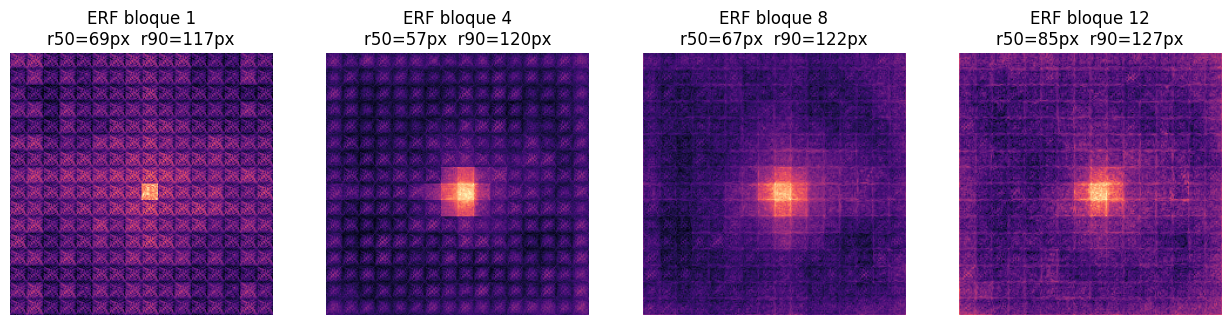

 bloque  radio50_px  radio90_px  masa_en_parche_central_%
      1        69.4       117.2                       9.3
      4        57.4       120.0                      16.1
      8        67.4       121.8                       7.2
     12        85.0       127.1                       3.3
Referencia: un parche mide 14 px; la imagen completa mide 224 px (radio máximo ≈ 158 px).


In [ ]:
def erf(m, x, bloque):
    x = x.clone().requires_grad_(True)
    hs = m(pixel_values=x, output_hidden_states=True).hidden_states
    centro = 1 + (G // 2) * G + G // 2                       # índice del token del parche central (+1 por el CLS)
    g, = torch.autograd.grad(hs[bloque][:, centro, :].sum(), x)
    return g.abs().sum(1).mean(0).cpu().numpy()             # (H, W)

def radio_masa(mapa, frac):
    H, W = mapa.shape; yy, xx = np.mgrid[0:H, 0:W]
    r = np.sqrt((yy - H / 2) ** 2 + (xx - W / 2) ** 2).ravel(); m = mapa.ravel()
    orden = np.argsort(r); acumulado = np.cumsum(m[orden]) / m.sum()
    return float(r[orden][np.searchsorted(acumulado, frac)])

n_erf = min(16, len(idx_te))
x_erf = torch.stack([dataset[i][0] for i in idx_te[:n_erf]]).to(DEVICE)
bloques_erf = [1, 4, 8, 12]; res_erf = []
fig, axes = plt.subplots(1, len(bloques_erf), figsize=(3.2 * len(bloques_erf), 3.2))
for ax, b in zip(axes, bloques_erf):
    mapa = erf(modelo, x_erf, b)
    r50, r90 = radio_masa(mapa, .5), radio_masa(mapa, .9)
    res_erf.append({'bloque': b, 'radio50_px': round(r50, 1), 'radio90_px': round(r90, 1),
                    'masa_en_parche_central_%': round(100 * mapa[(G // 2) * 14:(G // 2 + 1) * 14, (G // 2) * 14:(G // 2 + 1) * 14].sum() / mapa.sum(), 1)})
    ax.imshow(np.log1p(mapa / mapa.max() * 1e3), cmap='magma'); ax.set_title(f'ERF bloque {b}\nr50={r50:.0f}px  r90={r90:.0f}px'); ax.axis('off')
plt.tight_layout(); plt.savefig('figures/A5_erf.png', dpi=120); plt.show()
df_erf = pd.DataFrame(res_erf); df_erf.to_csv('results/A5_erf.csv', index=False); print(df_erf.to_string(index=False))
print(f'Referencia: un parche mide 14 px; la imagen completa mide {IMG_SIZE} px (radio máximo ≈ {IMG_SIZE / np.sqrt(2):.0f} px).')

**Para el cuaderno:** compara cómo crece el radio con la profundidad y qué % del gradiente queda en el propio parche central. Si en los primeros bloques casi todo queda en el parche central y en los últimos se reparte por la imagen, el modelo empieza "local" y se vuelve "global" aunque teóricamente pudiera mirar todo desde el inicio. Recuerda que cada píxel original de EuroSAT ocupa ~3.5 px tras el redimensionado.

---
## 4. Línea base: DINOv2 congelado + clasificador lineal
**Representación (decisión):** concatenar el token **CLS** (tras la norma final) y la **media de los tokens de parche** → vector de 768. Es el protocolo de *linear probing* que usa DINOv2 en su artículo. Se usa la misma representación en la condición LoRA.

Como el backbone está congelado y no hay data augmentation, las características se calculan **una sola vez** y se guardan (*caching*). Entrenar sobre ellas es equivalente a pasar las imágenes por el modelo en cada época, pero mucho más rápido.

In [ ]:
def representacion(ultima):              # ultima = last_hidden_state (B, 257, 384), ya normalizado
    return torch.cat([ultima[:, 0], ultima[:, 1:].mean(1)], dim=1)   # (B, 768)

@torch.no_grad()
def extraer(m, dl):
    feats, ys = [], []
    for x, y in tqdm(dl, leave=False):
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USAR_AMP):
            out = m(pixel_values=x.to(DEVICE, non_blocking=True)).last_hidden_state
        feats.append(representacion(out).float().cpu()); ys.append(y)
    return torch.cat(feats), torch.cat(ys)

ruta_cache = f'results/features_cache_seed{SEMILLA}' + (f'_max{MAX_POR_CLASE}' if MAX_POR_CLASE else '') + '.pt'
if os.path.exists(ruta_cache):
    cache = torch.load(ruta_cache)
else:
    t0 = time.time(); cache = {k: extraer(modelo, d) for k, d in (('train', dl_tr), ('val', dl_va), ('test', dl_te))}
    cache['segundos'] = time.time() - t0; torch.save(cache, ruta_cache)
print({k: tuple(v[0].shape) for k, v in cache.items() if k != 'segundos'}, f"| extracción: {cache['segundos']:.0f} s")

  0%|          | 0/296 [00:00<?, ?it/s]

  0%|          | 0/64 [00:00<?, ?it/s]

  0%|          | 0/64 [00:00<?, ?it/s]

{'train': (18900, 768), 'val': (4050, 768), 'test': (4050, 768)} | extracción: 61 s


In [ ]:
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

def metricas(y, p):
    return {'accuracy': accuracy_score(y, p), 'macro_f1': f1_score(y, p, average='macro')}

def entrenar_cabeza_cache(cache, epocas=EPOCAS, lr=LR):
    fijar_semilla()
    cabeza = nn.Linear(cache['train'][0].shape[1], len(CLASES)).to(DEVICE)
    opt = torch.optim.AdamW(cabeza.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    Xtr, ytr = cache['train']; Xva, yva = cache['val']
    g = torch.Generator(); g.manual_seed(SEMILLA)
    hist, mejor = [], (-1, None)
    for ep in range(epocas):
        cabeza.train()
        for i in torch.randperm(len(Xtr), generator=g).split(BATCH):
            loss = F.cross_entropy(cabeza(Xtr[i].to(DEVICE)), ytr[i].to(DEVICE))
            opt.zero_grad(); loss.backward(); opt.step()
        cabeza.eval()
        with torch.no_grad(): pva = cabeza(Xva.to(DEVICE)).argmax(1).cpu()
        m = metricas(yva, pva); hist.append({'epoca': ep + 1, 'loss_train': loss.item(), **{f'val_{k}': v for k, v in m.items()}})
        if m['macro_f1'] > mejor[0]: mejor = (m['macro_f1'], {k: v.clone() for k, v in cabeza.state_dict().items()})
    cabeza.load_state_dict(mejor[1])          # criterio de selección: mejor macro-F1 en validación
    return cabeza, pd.DataFrame(hist)

t0 = time.time()
cabeza_base, hist_base = entrenar_cabeza_cache(cache)
t_base = time.time() - t0 + cache['segundos']
with torch.no_grad(): p_base = cabeza_base(cache['test'][0].to(DEVICE)).argmax(1).cpu().numpy()
y_test = cache['test'][1].numpy()
res_base = {'condicion': 'linear probing (DINOv2 congelado)', 'parametros_entrenables': sum(p.numel() for p in cabeza_base.parameters()),
            **{f'test_{k}': v for k, v in metricas(y_test, p_base).items()}, 'segundos_entrenamiento': t_base}
torch.save(cabeza_base.state_dict(), 'checkpoints/cabeza_base.pt')
print(hist_base.round(4).to_string(index=False)); print('\nTEST:', {k: round(v, 4) if isinstance(v, float) else v for k, v in res_base.items()})
print(classification_report(y_test, p_base, target_names=CLASES, digits=3))

 epoca  loss_train  val_accuracy  val_macro_f1
     1      0.1057        0.9484        0.9464
     2      0.0098        0.9568        0.9548
     3      0.0542        0.9595        0.9573
     4      0.1642        0.9568        0.9552
     5      0.1647        0.9600        0.9580
     6      0.1640        0.9635        0.9618
     7      0.0712        0.9617        0.9598
     8      0.0348        0.9617        0.9601

TEST: {'condicion': 'linear probing (DINOv2 congelado)', 'parametros_entrenables': 7690, 'test_accuracy': 0.96, 'test_macro_f1': 0.958, 'segundos_entrenamiento': 64.3626}
                      precision    recall  f1-score   support

          AnnualCrop      0.960     0.969     0.965       450
              Forest      0.989     0.987     0.988       450
HerbaceousVegetation      0.972     0.936     0.954       450
             Highway      0.890     0.949     0.919       375
          Industrial      0.986     0.971     0.978       375
             Pasture      0.933 

---
## 5. Fase B (preliminar) — LoRA en Q y V de los 2 últimos bloques

### 5.1 Hipótesis (escrita ANTES de ejecutar)
> ⚠️ **Completen esto antes de correr la sección 5.3.** La consigna evalúa el modelo mental: qué esperaban y por qué, contrastado con lo que pasó. Copien lo mismo en `DESIGN_LOG.md`.

- **H1 (de la propuesta E1):** adaptar Q y V en los 2 últimos bloques con LoRA aumentará el **macro-F1** respecto al linear probing.
- **Por qué lo esperamos:** las features de DINOv2 se aprendieron con imágenes naturales; las imágenes satelitales a 64 px (texturas, vista cenital, sin objetos centrados) son otro dominio. Ajustar cómo atienden los últimos bloques podría adaptar la representación con muy pocos parámetros.
- **Magnitud esperada** (⚠️ *completada el 21/10/2026, después de ejecutar; basada solo en literatura y diseño, sin valor confirmatorio*):
  - **Base: macro-F1 0.94–0.97.** El fine-tuning completo de ResNet-50 en EuroSAT RGB llega a 98.57 % [Helber et al., 2019]; un clasificador lineal sobre features congeladas debería quedar 2–4 pts debajo. A 64 px cada parche de 14 px cubre ~4×4 px originales, lo que limita la representación.
  - **Δ (LoRA − base): +0.5 a +2.0 pts.** LoRA agrega solo 24,576 parámetros (0.11 %) en 2 de 12 bloques: puede cerrar parte de la brecha hasta el techo, no toda. En Hu et al. (2021) LoRA se acerca al fine-tuning completo aplicándolo en todas las capas; aquí solo en 2. Cerca del 97 % hay efecto techo.
  - **Se rechaza si Δ < 0.6 pts** (≈ 2 errores estándar del macro-F1 con 4,050 imágenes: √(0.96×0.04/4050) ≈ 0.3 pts) o si la mejora de validación no se mantiene en test.
- **Riesgo previsto:** con más parámetros entrenables, LoRA puede sobreajustar a la partición interna y luego empeorar en regiones nuevas (Fase C).

### 5.2 Implementación de LoRA (propia, ~20 líneas, para poder explicarla en la oral)
W_adaptada = W + (α/r) · B·A, con A ∈ ℝ^(r×384) y B ∈ ℝ^(384×r). **B empieza en ceros**, así que al inicio el modelo es idéntico al original. W y el bias quedan congelados.

In [ ]:
class LoRALinear(nn.Module):
    def __init__(self, base: nn.Linear, r=8, alpha=8, dropout=0.0):
        super().__init__()
        self.base, self.r, self.escala = base, r, alpha / r
        for p in self.base.parameters(): p.requires_grad_(False)       # W y b congelados
        dev, dt = base.weight.device, base.weight.dtype                # mismo dispositivo y tipo que W (GPU)
        self.A = nn.Parameter(torch.empty(r, base.in_features, device=dev, dtype=dt))
        self.B = nn.Parameter(torch.zeros(base.out_features, r, device=dev, dtype=dt))  # B = 0 → actualización inicial nula

        nn.init.kaiming_uniform_(self.A, a=math.sqrt(5))                # misma inicialización que nn.Linear / LoRA original
        self.drop = nn.Dropout(dropout) if dropout > 0 else nn.Identity()
    def forward(self, x):
        return self.base(x) + (self.drop(x) @ self.A.T @ self.B.T) * self.escala
    @torch.no_grad()
    def fusionar(self):                                                # W' = W + escala·B·A (sin costo en inferencia)
        self.base.weight += self.escala * (self.B @ self.A); return self.base

NOMBRES_Q, NOMBRES_V = ('query', 'q_proj'), ('value', 'v_proj')        # nombres según la versión de transformers

def aplicar_lora(m, bloques=LORA_BLOQUES, r=LORA_RANGO, alpha=LORA_ALPHA, dropout=LORA_DROPOUT):
    reemplazados = []
    for b in bloques:
        for nombre, sub in list(m.encoder.layer[b].named_modules()):
            hoja = nombre.split('.')[-1]
            if isinstance(sub, nn.Linear) and hoja in NOMBRES_Q + NOMBRES_V:
                padre = m.encoder.layer[b].get_submodule(nombre.rsplit('.', 1)[0]) if '.' in nombre else m.encoder.layer[b]
                setattr(padre, hoja, LoRALinear(sub, r, alpha, dropout)); reemplazados.append(f'bloque {b + 1}: {nombre}')
    assert len(reemplazados) == 2 * len(bloques), f'No se encontraron Q y V: {reemplazados}'
    return reemplazados

fijar_semilla()
modelo_lora = cargar_dinov2()
for p in modelo_lora.parameters(): p.requires_grad_(False)
print('LoRA aplicado en:', aplicar_lora(modelo_lora))
params_lora = sum(p.numel() for p in modelo_lora.parameters() if p.requires_grad)
print(f'Parámetros LoRA entrenables: {params_lora:,} ({100 * params_lora / contar(modelo):.3f} % del backbone)')

# Verificación pedida en la propuesta: con B = 0 la salida debe ser IDÉNTICA al modelo base
with torch.no_grad():
    dif = (modelo_lora(pixel_values=x_vis).last_hidden_state - modelo(pixel_values=x_vis).last_hidden_state).abs().max().item()
print(f'Diferencia máxima con el modelo base al inicializar: {dif:.2e}  →', 'OK' if dif < 1e-5 else 'REVISAR')

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

LoRA aplicado en: ['bloque 11: attention.q_proj', 'bloque 11: attention.v_proj', 'bloque 12: attention.q_proj', 'bloque 12: attention.v_proj']
Parámetros LoRA entrenables: 24,576 (0.111 % del backbone)
Diferencia máxima con el modelo base al inicializar: 0.00e+00  → OK


### 5.3 Entrenamiento con el mismo presupuesto
Se controla todo menos la intervención: misma partición, preprocesamiento (sin augmentation), representación (CLS + media de parches), cabeza lineal inicializada con la misma semilla, optimizador (AdamW, lr y weight decay), batch, **número de épocas** y criterio de selección (mejor macro-F1 en validación).

**Eficiencia:** los bloques 1–10 no tienen parámetros entrenables, así que se ejecutan con `torch.no_grad()` y solo se hace backprop por los bloques 11–12 y la cabeza.

In [ ]:
def adelante_lora(m, x):
    with torch.no_grad():                                   # bloques sin LoRA: sin gradiente
        h = m.embeddings(x)
        for capa in m.encoder.layer[:min(LORA_BLOQUES)]: h = salida_bloque(capa(h))
    for capa in m.encoder.layer[min(LORA_BLOQUES):]: h = salida_bloque(capa(h))
    return representacion(m.layernorm(h))

with torch.no_grad():                                        # comprobar que el atajo da lo mismo que el forward completo
    ref = representacion(modelo_lora(pixel_values=x_vis).last_hidden_state)
    print('¿adelante_lora == forward completo?', torch.allclose(adelante_lora(modelo_lora, x_vis), ref, atol=1e-4))

def entrenar_lora(m, epocas=EPOCAS, lr=LR):
    fijar_semilla()
    cabeza = nn.Linear(2 * m.config.hidden_size, len(CLASES)).to(DEVICE)   # misma inicialización que la línea base
    entrenables = [p for p in m.parameters() if p.requires_grad] + list(cabeza.parameters())
    opt = torch.optim.AdamW(entrenables, lr=lr, weight_decay=WEIGHT_DECAY)
    scaler = torch.amp.GradScaler('cuda', enabled=USAR_AMP)
    dl_tr_shuf = cargador(idx_tr, shuffle=True)
    hist, mejor = [], (-1, None)
    for ep in range(epocas):
        m.train(); cabeza.train()
        for x, y in tqdm(dl_tr_shuf, desc=f'época {ep + 1}', leave=False):
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USAR_AMP):
                loss = F.cross_entropy(cabeza(adelante_lora(m, x)), y)
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        m.eval(); cabeza.eval(); pv = []
        with torch.no_grad(), torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USAR_AMP):
            for x, _ in dl_va: pv.append(cabeza(adelante_lora(m, x.to(DEVICE))).argmax(1).cpu())
        mv = metricas(cache['val'][1], torch.cat(pv)); hist.append({'epoca': ep + 1, 'loss_train': loss.item(), **{f'val_{k}': v for k, v in mv.items()}})
        if mv['macro_f1'] > mejor[0]:
            mejor = (mv['macro_f1'], {'cabeza': {k: v.clone() for k, v in cabeza.state_dict().items()},
                                      'lora': {k: v.detach().clone() for k, v in m.named_parameters() if v.requires_grad}})
    cabeza.load_state_dict(mejor[1]['cabeza'])
    with torch.no_grad():
        for k, v in m.named_parameters():
            if v.requires_grad: v.copy_(mejor[1]['lora'][k])
    return cabeza, pd.DataFrame(hist), mejor[1]

t0 = time.time()
cabeza_lora, hist_lora, pesos_lora = entrenar_lora(modelo_lora)
t_lora = time.time() - t0
modelo_lora.eval(); pt = []
with torch.no_grad(), torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USAR_AMP):
    for x, _ in dl_te: pt.append(cabeza_lora(adelante_lora(modelo_lora, x.to(DEVICE))).argmax(1).cpu())
p_lora = torch.cat(pt).numpy()
res_lora = {'condicion': f'LoRA r={LORA_RANGO} Q,V bloques {[b + 1 for b in LORA_BLOQUES]}',
            'parametros_entrenables': params_lora + sum(p.numel() for p in cabeza_lora.parameters()),
            **{f'test_{k}': v for k, v in metricas(y_test, p_lora).items()}, 'segundos_entrenamiento': t_lora}
torch.save(pesos_lora, 'checkpoints/lora_y_cabeza.pt')
print(hist_lora.round(4).to_string(index=False)); print('\nTEST:', {k: round(v, 4) if isinstance(v, float) else v for k, v in res_lora.items()})

¿adelante_lora == forward completo? True


época 1:   0%|          | 0/296 [00:00<?, ?it/s]

época 2:   0%|          | 0/296 [00:00<?, ?it/s]

época 3:   0%|          | 0/296 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f2a00355da0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1655, in _shutdown_workers
    self._pin_memory_thread.join()
  File "/usr/lib/python3.13/threading.py", line 1088, in join
    raise RuntimeError("cannot join current thread")
RuntimeError: cannot join current thread
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f2a00355da0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/proc

época 4:   0%|          | 0/296 [00:00<?, ?it/s]

... (2 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f2a00355da0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f2a00355da0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

época 7:   0%|          | 0/296 [00:00<?, ?it/s]

época 8:   0%|          | 0/296 [00:00<?, ?it/s]

 epoca  loss_train  val_accuracy  val_macro_f1
     1      0.1529        0.9674        0.9667
     2      0.0343        0.9723        0.9713
     3      0.0003        0.9753        0.9743
     4      0.0042        0.9731        0.9720
     5      0.0034        0.9721        0.9717
     6      0.0798        0.9733        0.9723
     7      0.0003        0.9763        0.9752
     8      0.0060        0.9733        0.9725

TEST: {'condicion': 'LoRA r=8 Q,V bloques [11, 12]', 'parametros_entrenables': 32266, 'test_accuracy': 0.9728, 'test_macro_f1': 0.9714, 'segundos_entrenamiento': 453.9821}


### 5.4 Comparación controlada

                        condicion  parametros_entrenables  test_accuracy  test_macro_f1  segundos_entrenamiento
linear probing (DINOv2 congelado)                    7690         0.9600         0.9580                    64.0
    LoRA r=8 Q,V bloques [11, 12]                   32266         0.9728         0.9714                   454.0

Δ macro-F1 (LoRA − base) = +1.33 puntos | errores en test: base 162, LoRA 110 de 4050

                         base    LoRA       Δ
AnnualCrop            0.9646  0.9648  0.0002
Forest                0.9878  0.9889  0.0012
HerbaceousVegetation  0.9536  0.9609  0.0073
Highway               0.9187  0.9772  0.0585
Industrial            0.9785  0.9842  0.0057
Pasture               0.9333  0.9379  0.0046
PermanentCrop         0.9349  0.9423  0.0074
Residential           0.9789  0.9877  0.0088
River                 0.9380  0.9751  0.0371
SeaLake               0.9922  0.9944  0.0022


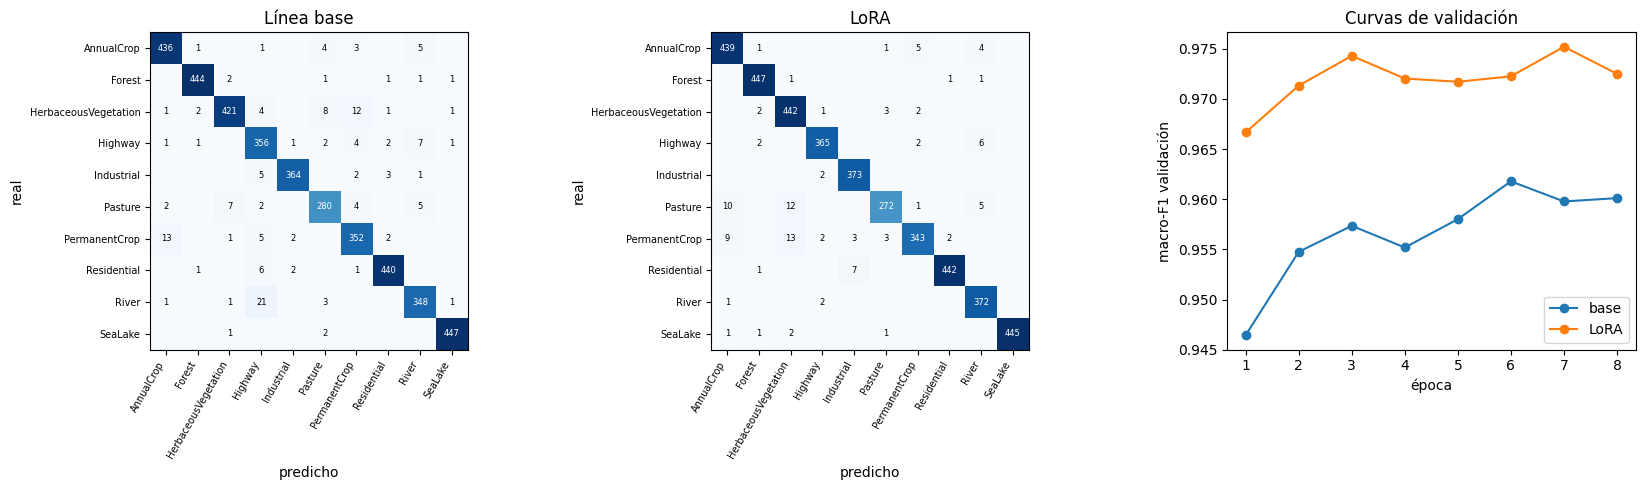

In [ ]:
comp = pd.DataFrame([res_base, res_lora])
comp['test_accuracy'] = comp['test_accuracy'].round(4); comp['test_macro_f1'] = comp['test_macro_f1'].round(4)
comp['segundos_entrenamiento'] = comp['segundos_entrenamiento'].round(0)
comp.to_csv('results/B1_comparacion.csv', index=False); print(comp.to_string(index=False))
delta = res_lora['test_macro_f1'] - res_base['test_macro_f1']
print(f'\nΔ macro-F1 (LoRA − base) = {100 * delta:+.2f} puntos | errores en test: base {int((p_base != y_test).sum())}, LoRA {int((p_lora != y_test).sum())} de {len(y_test)}')

# F1 por clase y matrices de confusión
f1_clase = pd.DataFrame({'base': f1_score(y_test, p_base, average=None), 'LoRA': f1_score(y_test, p_lora, average=None)}, index=CLASES)
f1_clase['Δ'] = f1_clase['LoRA'] - f1_clase['base']; f1_clase.round(4).to_csv('results/B2_f1_por_clase.csv'); print('\n', f1_clase.round(4).to_string())

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (t, p) in zip(axes[:2], [('Línea base', p_base), ('LoRA', p_lora)]):
    cm = confusion_matrix(y_test, p, labels=range(len(CLASES)))
    ax.imshow(cm, cmap='Blues'); ax.set_title(t)
    ax.set_xticks(range(len(CLASES))); ax.set_xticklabels(CLASES, rotation=60, ha='right', fontsize=7)
    ax.set_yticks(range(len(CLASES))); ax.set_yticklabels(CLASES, fontsize=7); ax.set_xlabel('predicho'); ax.set_ylabel('real')
    for i in range(len(CLASES)):
        for j in range(len(CLASES)):
            if cm[i, j]: ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=6, color='white' if cm[i, j] > cm.max() / 2 else 'black')
for h, n in [(hist_base, 'base'), (hist_lora, 'LoRA')]: axes[2].plot(h['epoca'], h['val_macro_f1'], 'o-', label=n)
axes[2].set_xlabel('época'); axes[2].set_ylabel('macro-F1 validación'); axes[2].legend(); axes[2].set_title('Curvas de validación')
plt.tight_layout(); plt.savefig('figures/B1_confusion_y_curvas.png', dpi=120); plt.show()

In [ ]:
# Costo de la intervención: latencia sin fusionar vs fusionada (LoRA se puede "fusionar" en W y no cuesta nada en inferencia)
lat_lora = medir_latencia(modelo_lora, 32 if DEVICE == 'cuda' else 16)
with torch.no_grad(): antes = adelante_lora(modelo_lora, x_vis)
for capa in modelo_lora.encoder.layer:
    for nombre, sub in list(capa.named_modules()):
        if isinstance(sub, LoRALinear):
            padre = capa.get_submodule(nombre.rsplit('.', 1)[0]) if '.' in nombre else capa
            setattr(padre, nombre.split('.')[-1], sub.fusionar())
with torch.no_grad(): despues = representacion(modelo_lora(pixel_values=x_vis).last_hidden_state)
print('¿El modelo fusionado da la misma salida que LoRA sin fusionar?', torch.allclose(antes, despues, atol=1e-3))
lat_fus = medir_latencia(modelo_lora, 32 if DEVICE == 'cuda' else 16)
lat_ref = medir_latencia(modelo, 32 if DEVICE == 'cuda' else 16)
df_costo = pd.DataFrame([{'modelo': 'base', **lat_ref}, {'modelo': 'LoRA sin fusionar', **lat_lora}, {'modelo': 'LoRA fusionado', **lat_fus}]).round(2)
df_costo.to_csv('results/B3_costo_lora.csv', index=False); print(df_costo[['modelo', 'batch', 'ms_por_imagen', 'memoria_pico_MB']].to_string(index=False))

json.dump({'base': res_base, 'lora': res_lora, 'delta_macro_f1': delta, 'config': {
    'epocas': EPOCAS, 'lr': LR, 'weight_decay': WEIGHT_DECAY, 'batch': BATCH, 'lora_rango': LORA_RANGO, 'lora_alpha': LORA_ALPHA,
    'lora_bloques_1indexados': [b + 1 for b in LORA_BLOQUES], 'max_por_clase': MAX_POR_CLASE, 'img_size': IMG_SIZE}, 'entorno': ENTORNO},
    open('results/B_resumen.json', 'w'), indent=2, default=float)
print('\nResultados guardados en results/ y figures/')

¿El modelo fusionado da la misma salida que LoRA sin fusionar? True
           modelo  batch  ms_por_imagen  memoria_pico_MB
             base     32           4.43           402.65
LoRA sin fusionar     32           4.35           402.81
   LoRA fusionado     32           4.41           402.65

Resultados guardados en results/ y figures/


### 5.5 Contraste con la hipótesis
| | Esperado (cualitativo: E1, 07/10 · numérico: escrito el 21/10, después de ejecutar) | Obtenido (test, 4,050 imágenes) | ¿Se cumple? |
|---|---|---|---|
| macro-F1 línea base | 0.94 – 0.97 | 0.9580 | Sí |
| macro-F1 LoRA | mayor que la línea base (≈ 0.95 – 0.99) | 0.9714 | **Sí** |
| Δ macro-F1 | +0.5 a +2.0 pts; rechazo si < 0.6 | **+1.33 pts** (errores: 162 → 110, −32 %) | **Sí** |

**Análisis:**
- **Ojo:** la predicción numérica se escribió después de ejecutar, así que el "Sí" de los rangos numéricos solo indica coherencia con la literatura, no una confirmación.
- **Ruido:** test de McNemar en el peor caso (sin predicciones pareadas): χ² = 9.56, p ≈ 0.002. Solo cubre la variabilidad del test, no la del entrenamiento (una sola semilla).
- **Dónde mejora:** Highway (+5.85 pts de F1) y River (+3.71). La confusión River → Highway baja de 21 a 2: las estructuras delgadas y alargadas se separan mejor tras adaptar la atención.
- **Dónde empeora:** aparecen confusiones nuevas entre vegetación (Pasture → AnnualCrop 2 → 10; PermanentCrop → HerbaceousVegetation 1 → 13). El recall de Pasture y PermanentCrop baja, aunque su F1 sube por precisión.
- **Sobreajuste:** la pérdida de entrenamiento llega a ~0.0003, pero el macro-F1 de validación se mantiene estable (0.972–0.975 desde la época 3).
- **Costo:** +24,576 parámetros (0.11 %), entrenamiento ×7 más lento, latencia de inferencia igual (4.43 vs 4.35 vs 4.41 ms/img; fusionado = mismo costo que la base).
- **Limitación principal:** la partición es aleatoria; la pregunta de investigación (regiones nuevas) se responde en la Fase C.

---
## 6. Pendientes para E3 (declararlos en el cuaderno)
1. **Partición geográfica (Fase C):** los JPG RGB no tienen coordenadas. Revisar `EuroSAT_MS.zip` (GeoTIFF georreferenciados) y vincular cada imagen RGB con su GeoTIFF por nombre de archivo para construir grupos por región. Si no es viable, rediseñar con otra fuente documentada (no reemplazar en silencio por una división aleatoria).
2. **Ablaciones de la intervención:** rango (4, 8, 16), qué bloques (últimos 2 vs 4), solo Q vs Q+V.
3. **Varias semillas** (3) para estimar la variación.
4. **Demo Streamlit** con los checkpoints de `checkpoints/`.